# Detección de fraude en tarjetas de crédito

Trabajo en prevención de fraude, así que quería ver qué tan lejos llega un modelo con un dataset público y, sobre todo, cómo elegir un umbral de alertas que tenga sentido para un equipo de operación.

Uso el dataset [Credit Card Fraud Detection](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud) de Kaggle: dos días de transacciones con tarjeta de clientes europeos. La mayoría de las columnas (V1 a V28) son componentes de PCA, así que están anonimizadas. Las únicas en crudo son `Time`, `Amount` y la etiqueta `Class`.

El plan:
1. Limpiar los datos (tienen duplicados).
2. Separar en train, validación y test.
3. Comparar regresión logística, random forest y XGBoost con PR-AUC en validación.
4. Elegir el umbral de alertas en validación.
5. Evaluar una sola vez en test y traducir el resultado a dinero y carga de trabajo.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (average_precision_score, precision_recall_curve,
                             confusion_matrix, classification_report)
from xgboost import XGBClassifier

SEED = 42

## 1. Datos

In [2]:
df = pd.read_csv('creditcard.csv')
print(df.shape)
df.head()

(284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [3]:
print(df['Class'].value_counts())
print(f"Tasa de fraude: {df['Class'].mean():.4%}")

Class
0    284315
1       492
Name: count, dtype: int64
Tasa de fraude: 0.1727%


Menos del 0.2% de las transacciones son fraude. Por eso el accuracy no sirve aquí: un modelo que nunca marca nada tendría más de 99.8%. En su lugar uso precision, recall y PR-AUC.

El dataset no tiene nulos, pero sí tiene filas duplicadas idénticas. Si las dejo, la misma transacción puede quedar en train y en test, y los resultados se ven mejores de lo que realmente son.

In [4]:
print("Nulos:", df.isnull().sum().sum())
print("Filas duplicadas:", df.duplicated().sum())

df = df.drop_duplicates().reset_index(drop=True)
print("Sin duplicados:", df.shape)
print(df['Class'].value_counts())

Nulos: 0
Filas duplicadas: 1081
Sin duplicados: (283726, 31)
Class
0    283253
1       473
Name: count, dtype: int64


In [5]:
# Monto por clase
df.groupby('Class')['Amount'].describe()

,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,283253.0,88.413575,250.379023,0.0,5.67,22.00,77.46,25691.16
1,473.0,123.871860,260.211041,0.0,1.00,9.82,105.89,2125.87


## 2. Separación en train / validación / test

60 / 20 / 20, estratificado para que cada parte conserve la misma tasa de fraude.

- **Train**: entrenar los modelos.
- **Validación**: comparar modelos y elegir el umbral.
- **Test**: se usa una sola vez, al final.

En la primera versión de este proyecto elegí el umbral viendo el test. Eso filtra información y hace que los números finales salgan demasiado optimistas, así que esta vez el test no se toca hasta el último paso.

In [6]:
X = df.drop(columns='Class')
y = df['Class']

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.4, stratify=y, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=SEED)

for nombre, parte in [('train', y_train), ('val', y_val), ('test', y_test)]:
    print(f"{nombre:5}  filas={len(parte):>7,}  fraudes={parte.sum():>4}")

train  filas=170,235  fraudes= 284
val    filas= 56,745  fraudes=  94
test   filas= 56,746  fraudes=  95


## 3. Comparación de modelos

Todos los modelos manejan el desbalance dándole más peso a la clase de fraude. La regresión logística va dentro de un pipeline con escalado, porque `Time` y `Amount` están en una escala muy distinta a las columnas V (sin eso el solver ni siquiera converge).

En XGBoost, poner `scale_pos_weight` igual a la proporción completa de clases (cerca de 600 aquí) llevó casi todas las probabilidades a los extremos en mi primer intento, así que pruebo varios valores y me quedo con el mejor en validación.

In [7]:
proporcion = (y_train == 0).sum() / (y_train == 1).sum()
print(f"Proporción de clases: {proporcion:.0f} a 1")

modelos = {
    'logistic_regression': make_pipeline(
        StandardScaler(),
        LogisticRegression(class_weight='balanced', max_iter=2000)),
    'random_forest': RandomForestClassifier(
        n_estimators=300, class_weight='balanced', min_samples_leaf=2,
        random_state=SEED, n_jobs=-1),
}

for w in [1, round(np.sqrt(proporcion)), round(proporcion)]:
    modelos[f'xgboost_w{w}'] = XGBClassifier(
        n_estimators=300, learning_rate=0.05, max_depth=5,
        scale_pos_weight=w, eval_metric='aucpr',
        random_state=SEED, n_jobs=-1)

Proporción de clases: 598 a 1


In [8]:
proba_val_modelos = {}
resultados = []

for nombre, modelo in modelos.items():
    modelo.fit(X_train, y_train)
    proba = modelo.predict_proba(X_val)[:, 1]
    proba_val_modelos[nombre] = proba
    resultados.append({'modelo': nombre, 'pr_auc_val': average_precision_score(y_val, proba)})

resultados = pd.DataFrame(resultados).sort_values('pr_auc_val', ascending=False)
resultados

,modelo,pr_auc_val
1,random_forest,0.796516
4,xgboost_w598,0.793120
2,xgboost_w1,0.786995
3,xgboost_w24,0.784625
0,logistic_regression,0.692296


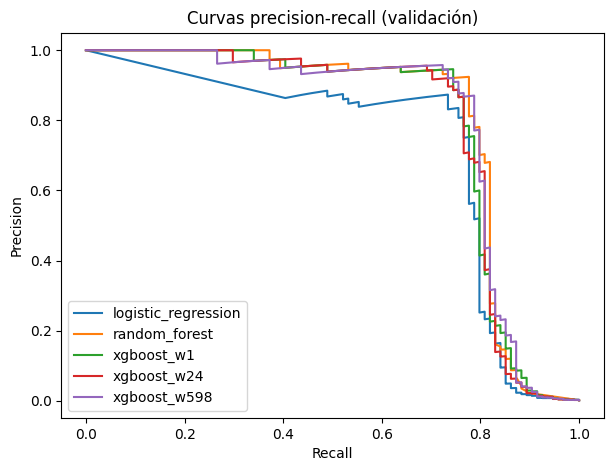

In [9]:
fig, ax = plt.subplots(figsize=(7, 5))
for nombre, proba in proba_val_modelos.items():
    prec, rec, _ = precision_recall_curve(y_val, proba)
    ax.plot(rec, prec, label=nombre)
ax.set_xlabel('Recall')
ax.set_ylabel('Precision')
ax.set_title('Curvas precision-recall (validación)')
ax.legend()
plt.show()

Random forest queda arriba, pero prácticamente empatado con XGBoost (0.797 contra 0.793). Con solo 94 fraudes en validación, una diferencia tan chica es ruido, así que no lo leería como que random forest es claramente mejor. Me quedo con él porque es el mejor resultado y es más sencillo de ajustar.

La regresión logística queda claramente atrás (0.69), lo cual tiene sentido: solo puede trazar una frontera lineal, y los modelos de árboles captan interacciones entre los componentes.

In [10]:
mejor_nombre = resultados.iloc[0]['modelo']
mejor_modelo = modelos[mejor_nombre]
print("Mejor modelo en validación:", mejor_nombre)

Mejor modelo en validación: random_forest


## 4. Elección del umbral

El corte de 0.5 que viene por defecto no necesariamente es el correcto. Bajarlo detecta más fraude pero manda más transacciones legítimas a revisión. Reviso ese balance en validación y me quedo con el umbral que tiene el mejor F1, que equilibra ambos.

En un equipo real esta decisión dependería de cuántas alertas pueden revisar los analistas al día y de cuánto cuesta un fraude que se escapa. F1 es un punto de partida razonable cuando no tienes esos números.

In [11]:
proba_val = proba_val_modelos[mejor_nombre]
n_fraudes_val = (y_val == 1).sum()

filas = []
for t in np.arange(0.05, 0.96, 0.05):
    pred = (proba_val >= t).astype(int)
    tp = ((pred == 1) & (y_val == 1)).sum()
    fp = ((pred == 1) & (y_val == 0)).sum()
    rec = tp / n_fraudes_val
    prec = tp / (tp + fp) if (tp + fp) else 0
    f1 = 2 * prec * rec / (prec + rec) if (prec + rec) else 0
    filas.append({'umbral': round(t, 2), 'recall': rec, 'precision': prec,
                  'f1': f1, 'tp': tp, 'fp': fp})

tabla_umbrales = pd.DataFrame(filas)
umbral = tabla_umbrales.loc[tabla_umbrales['f1'].idxmax(), 'umbral']
print("Umbral elegido:", umbral)
tabla_umbrales.round(3)

Umbral elegido: 0.35


,umbral,recall,precision,f1,tp,fp
0,0.05,0.819,0.647,0.723,77,42
1,0.10,0.798,0.781,0.789,75,21
2,0.15,0.777,0.811,0.793,73,17
3,0.20,0.777,0.839,0.807,73,14
4,0.25,0.777,0.890,0.830,73,9
5,0.30,0.777,0.912,0.839,73,7
6,0.35,0.777,0.924,0.844,73,6
7,0.40,0.755,0.922,0.830,71,6
8,0.45,0.734,0.920,0.817,69,6
9,0.50,0.734,0.932,0.821,69,5


## 5. Evaluación final en test

Primera y única vez que se usa el test.

In [12]:
proba_test = mejor_modelo.predict_proba(X_test)[:, 1]
pred_test = (proba_test >= umbral).astype(int)

print(f"PR-AUC en test: {average_precision_score(y_test, proba_test):.3f}\n")
print(confusion_matrix(y_test, pred_test))
print(classification_report(y_test, pred_test, digits=3))

PR-AUC en test: 0.857

[[56647     4]
 [   22    73]]
              precision    recall  f1-score   support

           0      1.000     1.000     1.000     56651
           1      0.948     0.768     0.849        95

    accuracy                          1.000     56746
   macro avg      0.974     0.884     0.924     56746
weighted avg      1.000     1.000     1.000     56746



## 6. Qué significa para el negocio

Los números que de verdad le importan a un equipo de fraude: cuánto dinero se detiene, cuánto se escapa y cuántas alertas tiene que revisar alguien.

In [13]:
mask_tp = (pred_test == 1) & (y_test == 1)
mask_fn = (pred_test == 0) & (y_test == 1)
mask_fp = (pred_test == 1) & (y_test == 0)

tp, fn, fp = mask_tp.sum(), mask_fn.sum(), mask_fp.sum()
detenido = X_test.loc[mask_tp, 'Amount'].sum()
perdido = X_test.loc[mask_fn, 'Amount'].sum()

print(f"Fraudes detectados: {tp} de {tp + fn} ({tp / (tp + fn):.0%})")
print(f"Fraudes que se escapan: {fn}")
print(f"Falsas alarmas: {fp}")
print()
print(f"Monto de fraude detenido: ${detenido:,.2f} ({detenido / (detenido + perdido):.0%} del total)")
print(f"Monto de fraude perdido:  ${perdido:,.2f}")
print()
print(f"Alertas generadas: {tp + fp}, de las cuales {tp / (tp + fp):.0%} son fraude real")

Fraudes detectados: 73 de 95 (77%)
Fraudes que se escapan: 22
Falsas alarmas: 4

Monto de fraude detenido: $9,638.17 (74% del total)
Monto de fraude perdido:  $3,334.89

Alertas generadas: 77, de las cuales 95% son fraude real


## 7. Qué variables pesan más

In [14]:
modelo_importancia = mejor_modelo[-1] if hasattr(mejor_modelo, 'steps') else mejor_modelo

if hasattr(modelo_importancia, 'feature_importances_'):
    importancias = pd.Series(modelo_importancia.feature_importances_, index=X.columns)
else:
    importancias = pd.Series(np.abs(modelo_importancia.coef_[0]), index=X.columns)

importancias.sort_values(ascending=False).head(10)

,0
V14,0.170435
V12,0.118369
V10,0.117580
V4,0.107402
V17,0.087446
V3,0.063675
V11,0.055864
V16,0.055239
V2,0.026191
V7,0.024132


Como V1 a V28 son componentes de PCA, no puedo decir qué significa cada una en términos de negocio (V14 no es "giro del comercio" ni nada parecido). Esto solo dice en qué componentes se apoya el modelo.

## Limitaciones

- El test tiene solo 95 casos de fraude, así que unas cuantas transacciones mueven las métricas varios puntos. Hay que tomar los resultados como una estimación, no como una cifra exacta.
- La separación es aleatoria, no por tiempo. En producción el modelo se entrenaría con datos pasados y se usaría en transacciones futuras, lo cual normalmente es más difícil.
- Al estar anonimizadas las variables, no hay ingeniería de variables real ni diseño de reglas basado en lógica de negocio. Eso es lo siguiente que quiero probar con un dataset que tenga campos de transacción en crudo.